## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Kevin Sun

**Date:** 10/14/2026

In [148]:
# Your Phase 1 solution to the problem goes here.

%pip install pandas
%pip install matplotlib seaborn scipy
%pip install scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import MinMaxScaler

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [149]:
# Q1.1

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

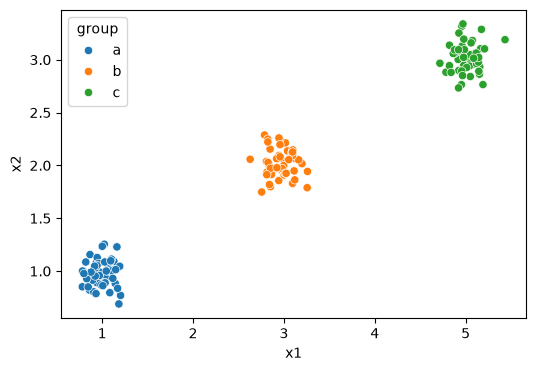

In [150]:
# Graph 1

fig, ax = plt.subplots(figsize=(6, 4))

sns.scatterplot(data=df0_125, x='x1', y='x2', hue='group', ax=ax)

plt.show()

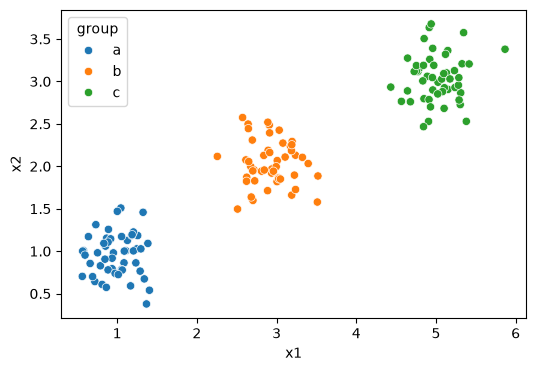

In [151]:
# Graph 2

fig, ax = plt.subplots(figsize=(6, 4))

sns.scatterplot(data=df0_25, x='x1', y='x2', hue='group', ax=ax)

plt.show()

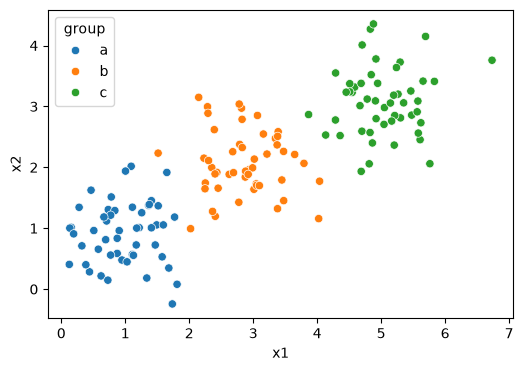

In [152]:
# Graph 3

fig, ax = plt.subplots(figsize=(6, 4))

sns.scatterplot(data=df0_5, x='x1', y='x2', hue='group', ax=ax)

plt.show()

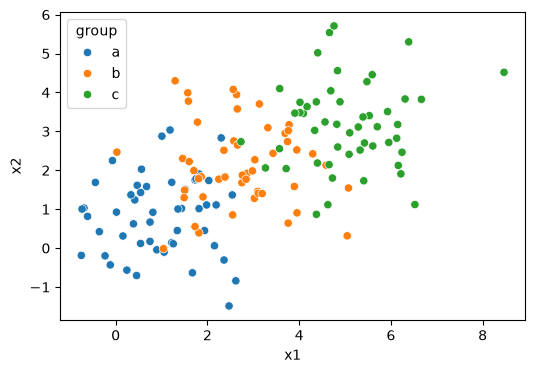

In [153]:
# Graph 4

fig, ax = plt.subplots(figsize=(6, 4))

sns.scatterplot(data=df1_0, x='x1', y='x2', hue='group', ax=ax)

plt.show()

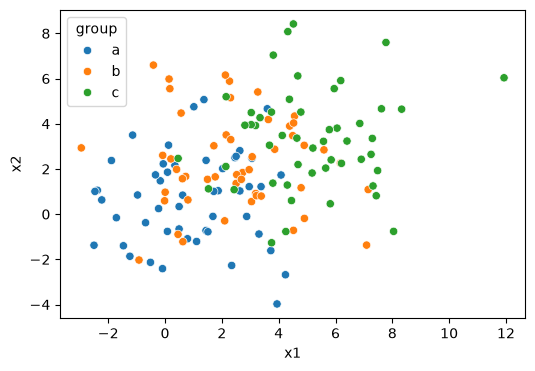

In [154]:
# Graph 5

fig, ax = plt.subplots(figsize=(6, 4))

sns.scatterplot(data=df2_0, x='x1', y='x2', hue='group', ax=ax)

plt.show()

**Q1.2**

As the noise goes up from 0.125 to 2.0, the clusters become more spread out (overlap) and less visually distinct. At low noise levels, the clusters are separated pretty clearly while at high noise levels the clusters overlap a lot.

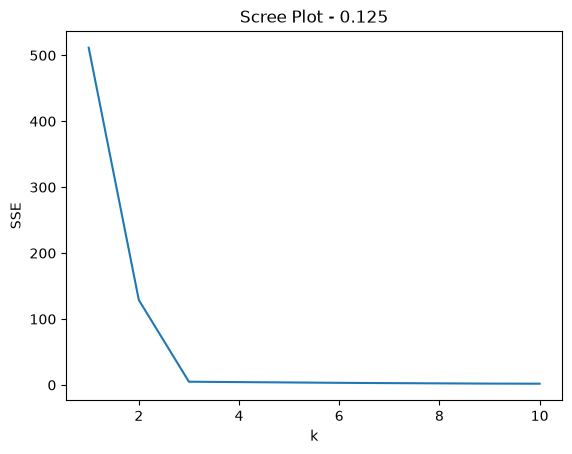

In [155]:
X = df0_125[['x1', 'x2']]

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot - 0.125", xlabel="k", ylabel="SSE")

plt.show()

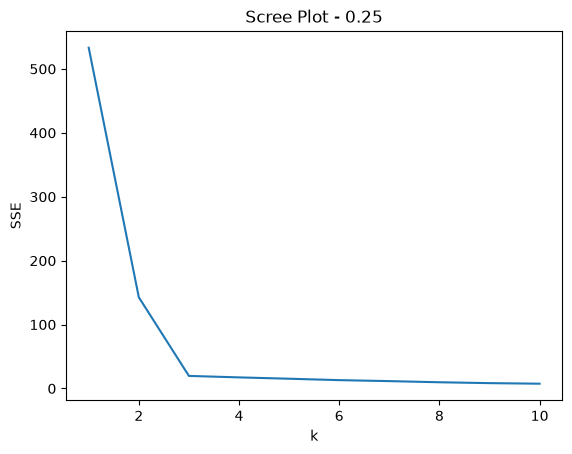

In [156]:
X = df0_25[['x1', 'x2']]

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot - 0.25", xlabel="k", ylabel="SSE")

plt.show()

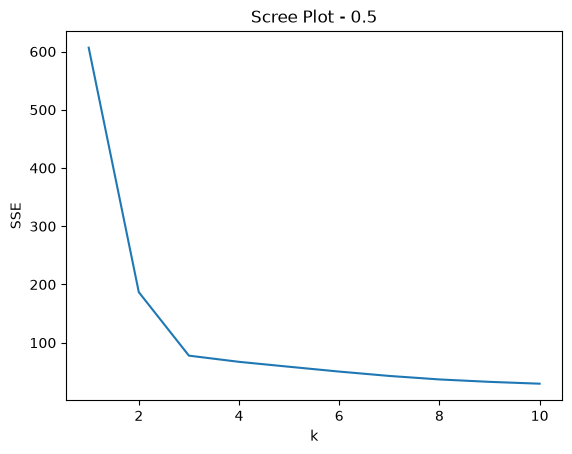

In [157]:
X = df0_5[['x1', 'x2']]

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot - 0.5", xlabel="k", ylabel="SSE")

plt.show()

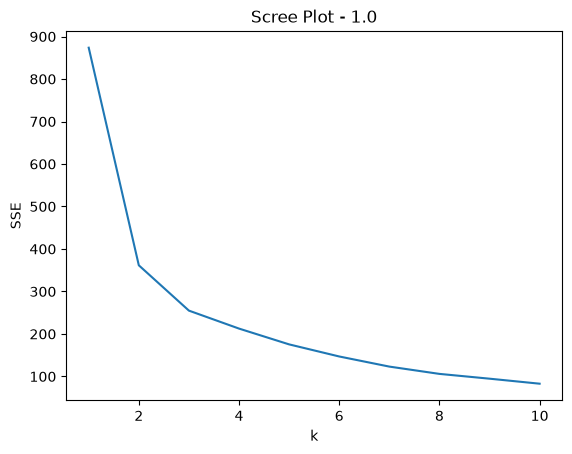

In [158]:
X = df1_0[['x1', 'x2']]

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot - 1.0", xlabel="k", ylabel="SSE")

plt.show()

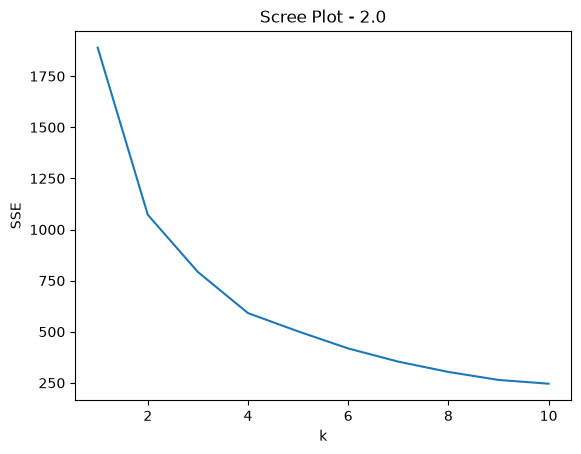

In [159]:
X = df2_0[['x1', 'x2']]

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot - 2.0", xlabel="k", ylabel="SSE")

plt.show()

**Q1.3**

As the noise increases, the presence of a distinct elbow becomes less clear and my ability to definitively select an optimal k value decreases. At low noise levels (0.125, 0.25, 0.5), I can clearly see the elbow around k=3. However, as the noise increases (1.0, 2.0), the reduction in SSE becomes less sharply defined (overall plots look more curved with rounded edges), which makes it hard for me to definitively select an optimal k value. Additionally, higher noise also increases the overall SSE (for graphs 1.0 and 2.0 the vertical axis scales in higher numbers).

**Q1.4**

The elbow method identifies the point where adding more clusters (k) produces diminishing returns in SSE. In this simulation, three clusters (k=3) was good because the data was originally generated around three centers. At low noise levels, the three groups were clearly separated, which produced a clear elbow around k=3 on those scree graphs. However, as the noise increased, the groups started overlapping and quickly became less visually distinct, so the elbow became harder to identify on those scree graphs. This shows that choosing k is easier when the clusters/groups are already clearly separated from the start.

In [160]:
df = pd.read_csv('/workspaces/A04-clustering/data/SIPRI Military Expenditure Database.csv')

print(df.dtypes,'\n')

df = df[df['Year'] == 2020].dropna().copy()

print(df.shape,'\n')

print(df.head(n=3))

index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object 

(148, 7) 

     index  Year      Country  Spending (2020 USD)  Percent of GDP  \
32      32  2020  Afghanistan           279.576955        0.013589   
66      66  2020      Albania           187.433234        0.012583   
100    100  2020      Algeria          9708.277440        0.066600   

     Percent of Government Spending  Spending per Capita  
32                         0.049728             7.181899  
66                         0.037952            65.126211  
100                        0.173924           221.392384  


In [161]:
print(df[['Spending (2020 USD)', 'Percent of GDP', 'Percent of Government Spending', 'Spending per Capita']].dtypes,'\n')

print(df[['Spending (2020 USD)', 'Percent of GDP', 'Percent of Government Spending', 'Spending per Capita']].describe(),'\n')

print(df['Year'].value_counts(),'\n')

print(df.isnull().sum())

Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object 

       Spending (2020 USD)  Percent of GDP  Percent of Government Spending  \
count           148.000000      148.000000                      148.000000   
mean          13153.747670        0.019619                        0.061510   
std           68005.236120        0.015033                        0.046207   
min               8.622460        0.000054                        0.004896   
25%             204.877177        0.010413                        0.031352   
50%             959.535443        0.015324                        0.047402   
75%            5289.998320        0.024327                        0.084681   
max          778397.200000        0.098470                        0.303027   

       Spending per Capita  
count           148.000000  
mean            268.264494  
std             430.434878

**Q2.1**

No further cleaning of the variables is required. This is because I ended up with 148 countries and also because all of the variable’s data types are already in the correct/required format.

In [162]:
spending_X_raw = df[['Spending (2020 USD)', 'Spending per Capita']]

spending_scaler = MinMaxScaler()

spending_X_scaled = pd.DataFrame(
    spending_scaler.fit_transform(spending_X_raw),
    columns=spending_X_raw.columns,
    index=spending_X_raw.index,
)

spending_X_scaled.agg(["min", "max"]).round(3)

,Spending (2020 USD),Spending per Capita
min,0.0,0.0
max,1.0,1.0


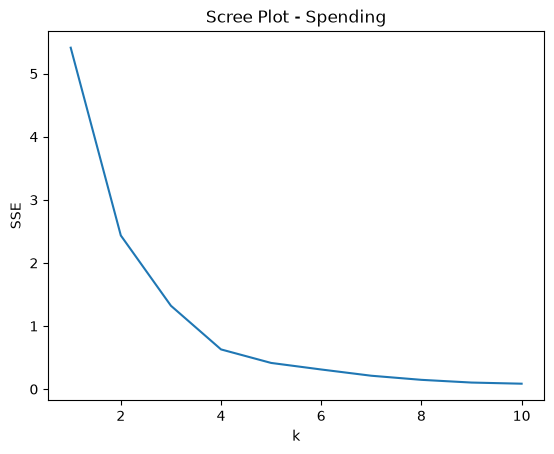

In [163]:
ks = np.arange(1, 11)
SSE1 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(spending_X_scaled).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE1).set(
    title="Scree Plot - Spending",
    xlabel="k",
    ylabel="SSE"
)
plt.show()

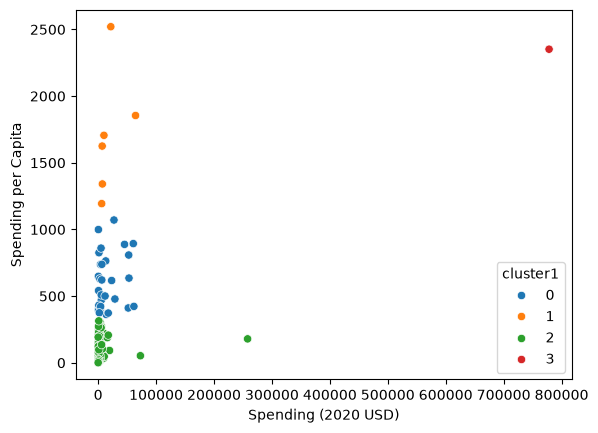

In [164]:
k1 = 4

km1 = KMeans(n_clusters=k1, max_iter=300, n_init=10, random_state=0)

df['cluster1'] = km1.fit_predict(spending_X_scaled)

sns.scatterplot(
    data=df,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    hue='cluster1',
    palette = 'tab10' # Better Colors
)

plt.show()

In [165]:
col1 = ['Spending (2020 USD)', 'Spending per Capita']
print(df.groupby('cluster1')[col1].describe())

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster1                                                                   
0                       30.0   17077.591354  20583.053357     405.790494   
1                        6.0   19443.362047  22861.507114    6095.708713   
2                      111.0    4859.185065  25405.739131       8.622460   
3                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster1                                                               
0           2294.039665    5857.060906   26296.001003   61712.537169   
1           7023.251766    8624.225729   18857.070183   64558.400000   
2            130.010211     382.464677    2297.032353  257973.429834   
3         778397.200000  778397.200

In [166]:
print(df['Country'].tolist(),'\n')

print(df.loc[df['Country'].str.contains('United States of America')])

['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Brunei', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia, The', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'India', 'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Korea, South', 'Kosovo', 'Kuwait', 'Kyrgyz Republic', 'Latvia', 'Lebanon', 'Lesotho', 'Liberia', 'Lithuania', 'Luxembourg', 'Mad

**Q2.2**

In the graph, I see that most of the clusters are located on the far left hand side of the graph. The clustering results show that most countries belong to Cluster 2, which has a relatively low total military spending and spending per capita compared to the other 3 clusters. Cluster 0 contains countries with moderate spending levels (total & per capita), while Cluster 1 contains a small number of countries with moderate total spending but relatively high spending per capita. The United States is the only country in Cluster 3 (outlier top right in graph), which shows that the US spends a **lot** of money on their military. Overall, the clusters appear to group countries based on their military spending levels. The cluster sizes are also a bit uneven.

In [167]:
percent_X_raw = df[['Percent of Government Spending', 'Percent of GDP']]

percent_scaler = MinMaxScaler()

percent_X_scaled = pd.DataFrame(
    percent_scaler.fit_transform(percent_X_raw),
    columns=percent_X_raw.columns,
    index=percent_X_raw.index,
)

percent_X_scaled.agg(["min", "max"]).round(3)

,Percent of Government Spending,Percent of GDP
min,0.0,0.0
max,1.0,1.0


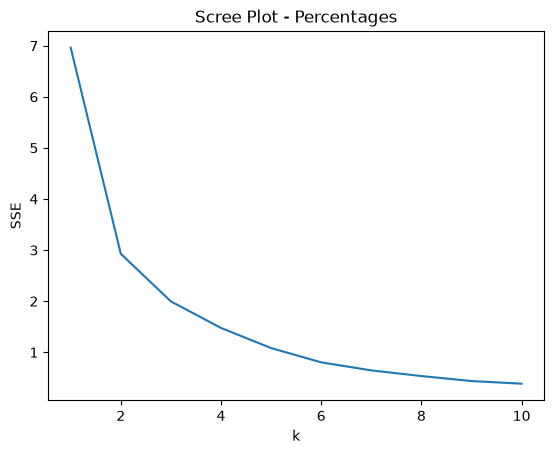

In [168]:
ks = np.arange(1, 11)
SSE2 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(percent_X_scaled).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE2).set(
    title="Scree Plot - Percentages",
    xlabel="k",
    ylabel="SSE"
)
plt.show()

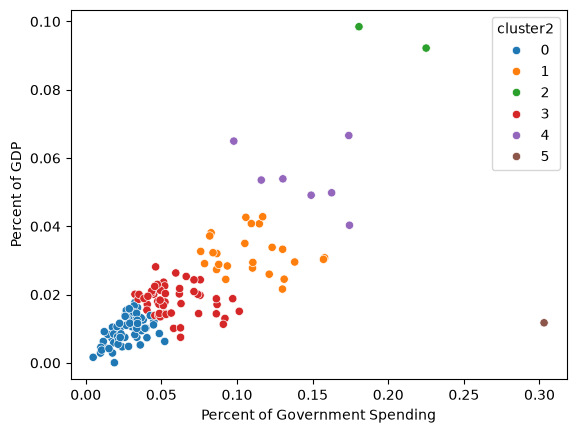

In [169]:
k2 = 6

km2 = KMeans(n_clusters=k2, max_iter=300, n_init=10, random_state=0)

df['cluster2'] = km2.fit_predict(percent_X_scaled)

sns.scatterplot(
    data=df,
    x='Percent of Government Spending',
    y='Percent of GDP',
    hue='cluster2',
    palette='tab10'
)


plt.show()

In [170]:
col2 = ['Percent of Government Spending', 'Percent of GDP']
print(df.groupby('cluster2')[col2].describe())

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  62.0  0.027491  0.010316  0.004896   
1                                  25.0  0.108523  0.023647  0.076005   
2                                   2.0  0.202852  0.031393  0.180654   
3                                  51.0  0.058296  0.017237  0.032524   
4                                   7.0  0.143451  0.029665  0.097882   
5                                   1.0  0.303027       NaN  0.303027   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.020772  0.027040  0.034004  0.052224           62.0  0.009654   
1         0.086676  0.109474  0.12

In [171]:
print(df.loc[df['Country'].str.contains('United States of America')])

      index  Year                   Country  Spending (2020 USD)  \
5540   5540  2020  United States of America             778397.2   

      Percent of GDP  Percent of Government Spending  Spending per Capita  \
5540        0.037179                        0.081976          2351.631858   

      cluster1  cluster2  
5540         3         1  


**Q2.3**

The overall graph looks different. Instead of having most of its points squished on the left hand side, like in Part 2, the points are spread out in an almost sort of confetti canon style-ish way. Compared with Part 2, clustering the percentage variables groups countries according to military spending relative to their government budgets and GDP rather than their absolute spending levels. Most countries fall into Clusters 0 and 3, which have relatively low military spending percentages compared to the other 4 clusters. Smaller clusters (2, 4, 5) contain countries that devote larger proportions of their government spending or GDP to the military. In these results, the US belongs to Cluster 1, with military spending accounting for about 8.20% of government spending and about 3.72% of GDP. Furthermore, the US shares a cluster with other countries, unlike in Part 2, where it formed its own single isolated cluster.

In [172]:
all_X_raw = df[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']]

all_scaler = MinMaxScaler()

all_X_scaled = pd.DataFrame(
    all_scaler.fit_transform(all_X_raw),
    columns=all_X_raw.columns,
    index=all_X_raw.index,
)

all_X_scaled.agg(["min", "max"]).round(3)

,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
min,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0


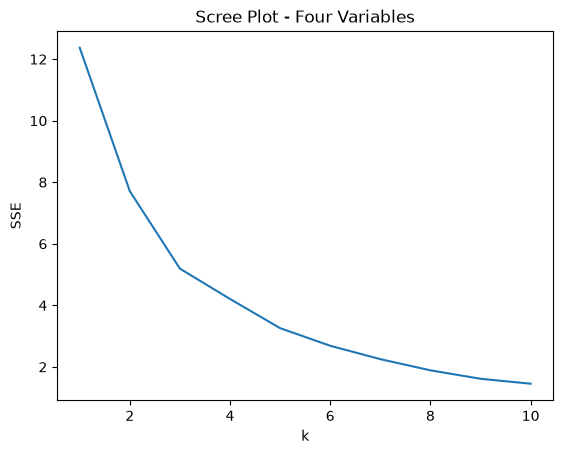

In [173]:
ks = np.arange(1, 11)
SSE3 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(all_X_scaled).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE3).set(
    title="Scree Plot - Four Variables",
    xlabel="k",
    ylabel="SSE"
)
plt.show()

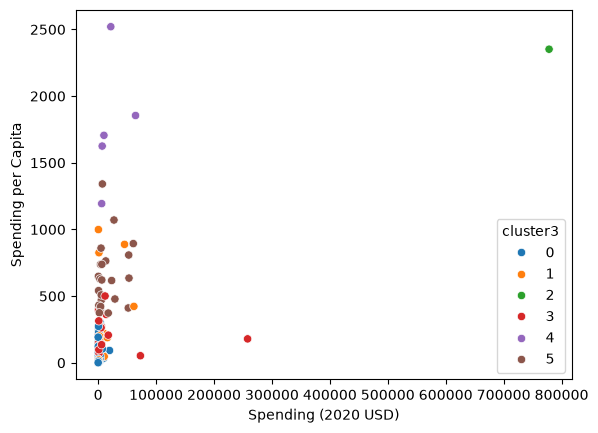

In [174]:
k3 = 6

km3 = KMeans(n_clusters=k3, max_iter=300, n_init=10, random_state=0)

df['cluster3'] = km3.fit_predict(all_X_scaled)

sns.scatterplot(
    data=df,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    hue='cluster3',
    palette='tab10'
)

plt.show()

In [175]:
col3 = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
print(df.groupby('cluster3')[col3].describe())

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster3                                                                   
0                       65.0    1355.055919   3001.122751       8.622460   
1                       20.0    8627.700242  16201.555992     198.530037   
2                        1.0  778397.200000           NaN  778397.200000   
3                       33.0   12551.478136  45915.639096      23.306688   
4                        5.0   21878.058451  24674.937388    6095.708713   
5                       24.0   16005.656033  19478.059176     405.790494   

                                                                      \
                    25%            50%            75%            max   
cluster3                                                               
0             78.965006     239.887164    1074.134515   19591.209004   
1            623.936771    

In [176]:
print(df.loc[df['Country'].str.contains('United States of America')])

      index  Year                   Country  Spending (2020 USD)  \
5540   5540  2020  United States of America             778397.2   

      Percent of GDP  Percent of Government Spending  Spending per Capita  \
5540        0.037179                        0.081976          2351.631858   

      cluster1  cluster2  cluster3  
5540         3         1         2  


**Q2.4**

Overall, the graph looks visually similar to Part 2 because it uses the same axes (Spending (2020) USD and Spending per Capita). However, the cluster/group assignments differ because the model now also considers the percentage variables. Using all four variables produces clusters that consider both the absolute levels of military spending and spending relative to government budgets and GDP. Most countries fall into Clusters 0 and 3, which generally have lower military spending levels/percentages compared to the other 4 clusters. Other clusters contain countries with higher spending per capita/larger military spending percentages. In these results, the US forms its own cluster (Cluster 2) again like in Part 2 because of its **really** high total military spending. Overall, combining all four variables provides a more detailed view of military spending patterns rather than just using either the absolute spending variables or the percentage variables by themselves.

**Q2.5**

Yes, the k-MC algorithm identified some useful patterns in military spending across countries. In Part 2, using absolute spending variables revealed differences in total military spending and spending per capita, with the US forming its own cluster due to its **really** high total spending. In Part 3, using percentage variables showed how countries prioritize military spending relative to their government budgets and GDP. This also showed that countries with different absolute spending levels can share similar spending proportions, as in these results (Part 3), the US belonged to a cluster with other countries. Finally, Part 4 combined all four variables, providing a more detailed view of military spending patterns but once again placing the US in its own singular cluster. Overall, these results/findings show that countries can have different military spending patterns depending on whether absolute (total) spending or relative (percentage) spending is considered. However, the clusters were not always evenly distributed, and the results describe similarities between countries but don’t really explain why their spending patterns actually differ.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 638b1feda846af71a9ca71731e4d5491d0671549
- **AI tool and model used:** ChatGPT-GPT-6

### *Prompts used

1. Hey chat I’m working on some data science problems. Here is the first problem [pastes in the entirety of Question 1]. For this problem can you just check to see if my code for the scatterplots and scree plots are correct or if I can make the code more efficient [pastes in all my code for the scatterplots and scree plots]. You don’t need to worry about any of the analysis questions so please just focus on the code. By the way, I’ve already imported and installed all the tools I need like pandas, matplotlib, scikit-learn, etc.
2. Here is the second problem [pastes in the entirety of Question 2]. Again just please focus on correcting/improving the code, no need to worry about any of the analysis questions. Let’s start with question 2.1 [pastes in all my code].
3. Now question 2.2 [pastes in all my code].
4. Onto question 2.3 [pastes in all my code].
5. Now lastly, question 2.4 [pastes in all my code].

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Combine the scatterplots into one code block. Instead of creating each scatterplot separately, you can store your five dataframes in a dictionary and use a loop to generate all five plots with titles.
2. Instead of generating five separate scree plots, you can plot all five SSE curves on a single graph to see how increasing noise affects the elbow point and clustering performance.
3. I'd use this cleaner version for Question 2.1. Most of your code is useful, but a few lines are redundant because they repeat checks you've already performed.
4. You can add a title to each scatterplot (in reference to my k Means scatterplots)
5. You don’t need print(df['Country'].tolist(),'\n')

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Normally, I like having graphs separated from each other for visualization. However, since I need to compare these scatterplots for Question 1.2, having them all side by side is really helpful. I verified by looking at my graphs and comparing them with AI's outputted graphs. |
| 2 | Accept | Again, since I need to compare these scree plots for Question 1.3, having them all on one graph makes it easier for me to do so, instead of having them all separated from each other. I verified by looking at my graphs and comparing them with AI's outputted graph. |
| 3 | Accept | This just makes the code more concise/efficient which is good. Verified by making sure the end output matched 148 rows. |
| 4 | Accept | This just makes my graphs better/more readable and understandable which is good. No need to verify this. |
| 5 | Accept | This just makes the code more concise/efficient which is good. Since I now know how the USA is named in the data, I do not need this line of code anymore. No need to verify this. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [177]:
# Your Phase 2 solution to the problem goes here.


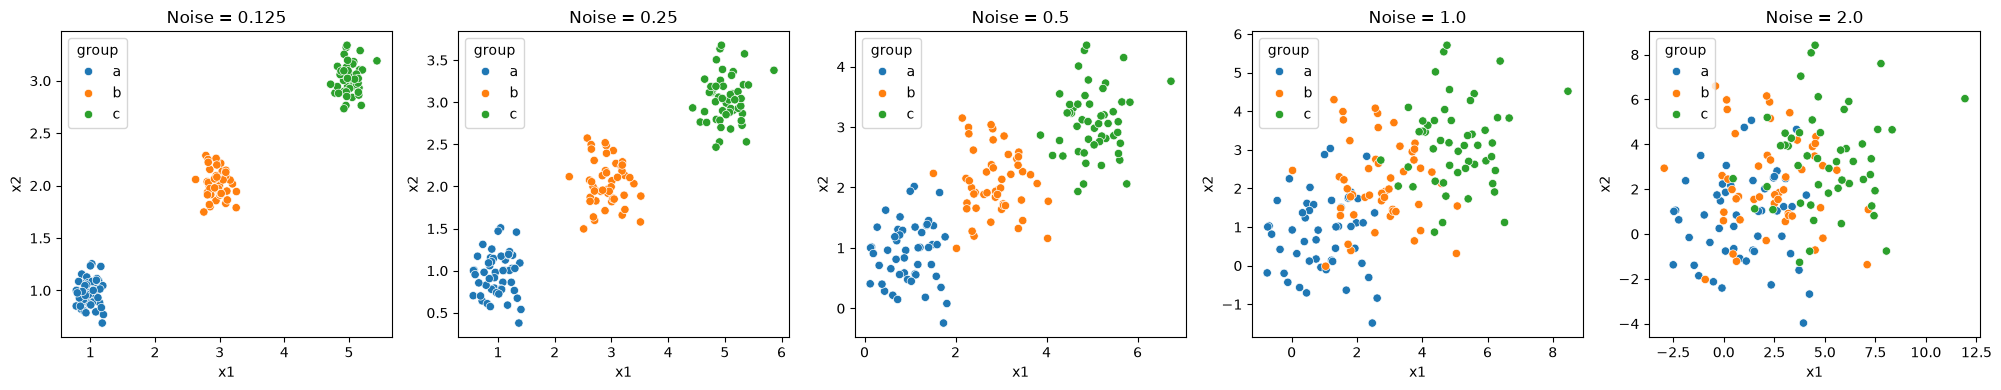

In [178]:
datasets = {
    'Noise = 0.125': df0_125,
    'Noise = 0.25': df0_25,
    'Noise = 0.5': df0_5,
    'Noise = 1.0': df1_0,
    'Noise = 2.0': df2_0
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, (title, df) in zip(axes, datasets.items()):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', ax=ax)
    ax.set_title(title)

plt.tight_layout()
plt.show()

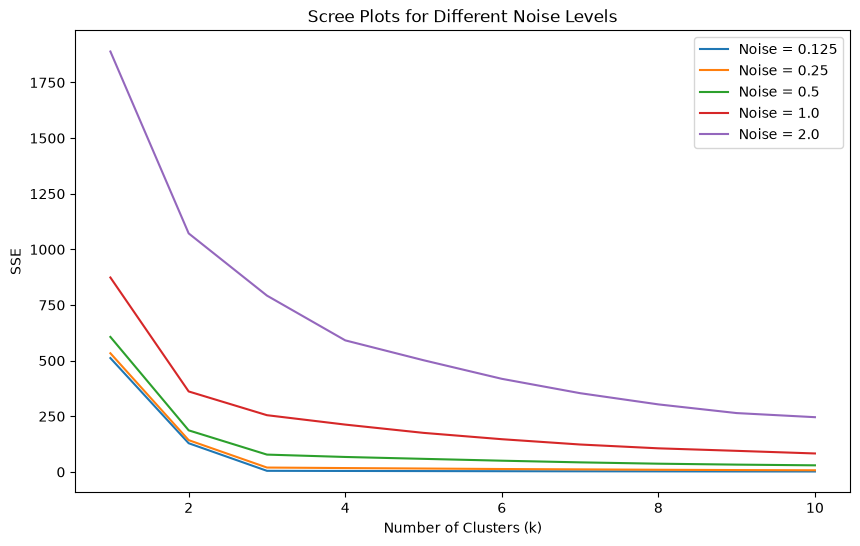

In [179]:
datasets = {
    'Noise = 0.125': df0_125,
    'Noise = 0.25': df0_25,
    'Noise = 0.5': df0_5,
    'Noise = 1.0': df1_0,
    'Noise = 2.0': df2_0
}

ks = np.arange(1, 11)

plt.figure(figsize=(10, 6))

for title, df in datasets.items():
    X = df[['x1', 'x2']]

    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]

    sns.lineplot(x=ks, y=SSE, label=title)

plt.title('Scree Plots for Different Noise Levels')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('SSE')
plt.legend()
plt.show()

In [180]:
df = pd.read_csv('/workspaces/A04-clustering/data/SIPRI Military Expenditure Database.csv')

print(df.dtypes, '\n')

df = df[df['Year'] == 2020].dropna().copy()

print(df.shape, '\n')

print(df[['Spending (2020 USD)',
          'Percent of GDP',
          'Percent of Government Spending',
          'Spending per Capita']].describe())

index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object 

(148, 7) 

       Spending (2020 USD)  Percent of GDP  Percent of Government Spending  \
count           148.000000      148.000000                      148.000000   
mean          13153.747670        0.019619                        0.061510   
std           68005.236120        0.015033                        0.046207   
min               8.622460        0.000054                        0.004896   
25%             204.877177        0.010413                        0.031352   
50%             959.535443        0.015324                        0.047402   
75%            5289.998320        0.024327                        0.084681   
max          778397.200000        0.098470             

In [181]:
spending_X_raw = df[['Spending (2020 USD)', 'Spending per Capita']]

spending_scaler = MinMaxScaler()

spending_X_scaled = pd.DataFrame(
    spending_scaler.fit_transform(spending_X_raw),
    columns=spending_X_raw.columns,
    index=spending_X_raw.index,
)

spending_X_scaled.agg(["min", "max"]).round(3)

,Spending (2020 USD),Spending per Capita
min,0.0,0.0
max,1.0,1.0


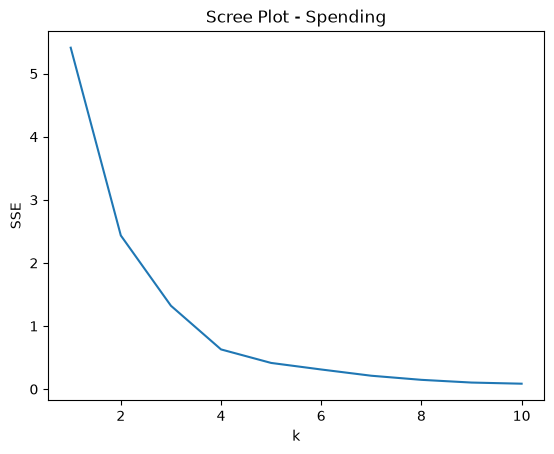

In [182]:
ks = np.arange(1, 11)
SSE1 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(spending_X_scaled).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE1).set(
    title="Scree Plot - Spending",
    xlabel="k",
    ylabel="SSE"
)
plt.show()

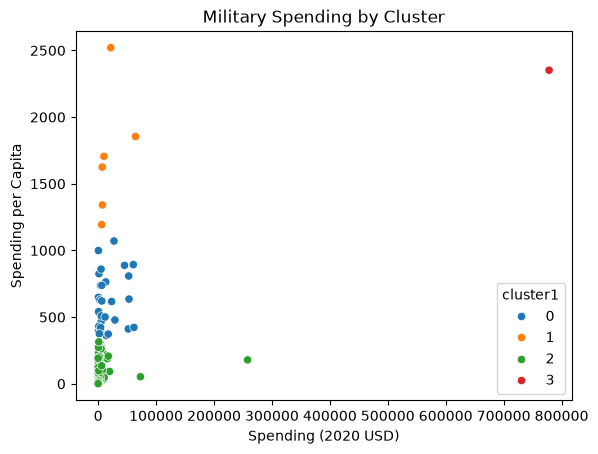

In [183]:
k1 = 4

km1 = KMeans(n_clusters=k1, max_iter=300, n_init=10, random_state=0)

df['cluster1'] = km1.fit_predict(spending_X_scaled)

sns.scatterplot(
    data=df,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    hue='cluster1',
    palette = 'tab10' # Better Colors
)

plt.title('Military Spending by Cluster')
plt.show()

In [184]:
col1 = ['Spending (2020 USD)', 'Spending per Capita']
print(df.groupby('cluster1')[col1].describe())

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster1                                                                   
0                       30.0   17077.591354  20583.053357     405.790494   
1                        6.0   19443.362047  22861.507114    6095.708713   
2                      111.0    4859.185065  25405.739131       8.622460   
3                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster1                                                               
0           2294.039665    5857.060906   26296.001003   61712.537169   
1           7023.251766    8624.225729   18857.070183   64558.400000   
2            130.010211     382.464677    2297.032353  257973.429834   
3         778397.200000  778397.200

In [185]:
print(df.loc[df['Country'].str.contains('United States of America')])

      index  Year                   Country  Spending (2020 USD)  \
5540   5540  2020  United States of America             778397.2   

      Percent of GDP  Percent of Government Spending  Spending per Capita  \
5540        0.037179                        0.081976          2351.631858   

      cluster1  
5540         3  


In [186]:
percent_X_raw = df[['Percent of Government Spending', 'Percent of GDP']]

percent_scaler = MinMaxScaler()

percent_X_scaled = pd.DataFrame(
    percent_scaler.fit_transform(percent_X_raw),
    columns=percent_X_raw.columns,
    index=percent_X_raw.index,
)

percent_X_scaled.agg(["min", "max"]).round(3)

,Percent of Government Spending,Percent of GDP
min,0.0,0.0
max,1.0,1.0


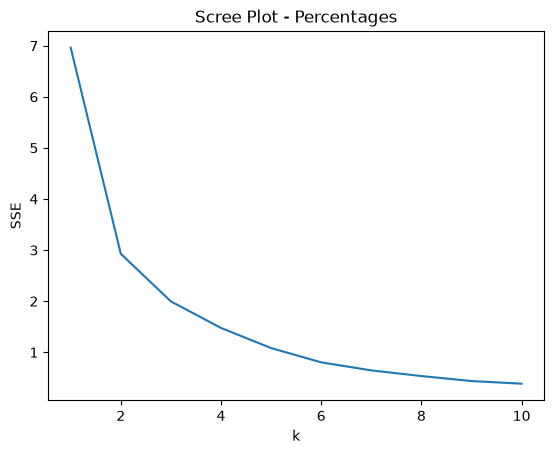

In [187]:
ks = np.arange(1, 11)
SSE2 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(percent_X_scaled).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE2).set(
    title="Scree Plot - Percentages",
    xlabel="k",
    ylabel="SSE"
)
plt.show()

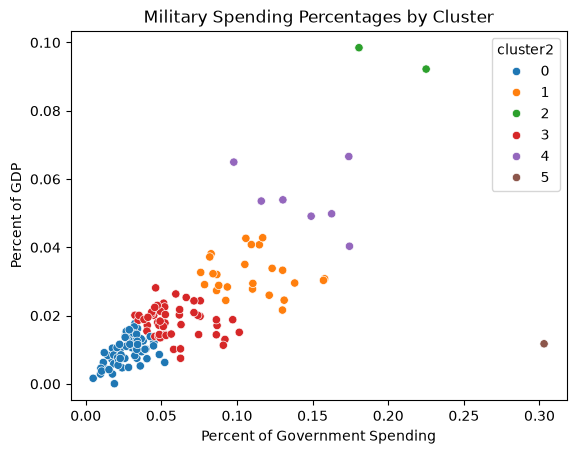

In [188]:
k2 = 6

km2 = KMeans(n_clusters=k2, max_iter=300, n_init=10, random_state=0)

df['cluster2'] = km2.fit_predict(percent_X_scaled)

sns.scatterplot(
    data=df,
    x='Percent of Government Spending',
    y='Percent of GDP',
    hue='cluster2',
    palette='tab10'
)

plt.title('Military Spending Percentages by Cluster')
plt.show()

In [189]:
col2 = ['Percent of Government Spending', 'Percent of GDP']
print(df.groupby('cluster2')[col2].describe())

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  62.0  0.027491  0.010316  0.004896   
1                                  25.0  0.108523  0.023647  0.076005   
2                                   2.0  0.202852  0.031393  0.180654   
3                                  51.0  0.058296  0.017237  0.032524   
4                                   7.0  0.143451  0.029665  0.097882   
5                                   1.0  0.303027       NaN  0.303027   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.020772  0.027040  0.034004  0.052224           62.0  0.009654   
1         0.086676  0.109474  0.12

In [190]:
print(df.loc[df['Country'].str.contains('United States of America')])

      index  Year                   Country  Spending (2020 USD)  \
5540   5540  2020  United States of America             778397.2   

      Percent of GDP  Percent of Government Spending  Spending per Capita  \
5540        0.037179                        0.081976          2351.631858   

      cluster1  cluster2  
5540         3         1  


In [191]:
all_X_raw = df[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']]

all_scaler = MinMaxScaler()

all_X_scaled = pd.DataFrame(
    all_scaler.fit_transform(all_X_raw),
    columns=all_X_raw.columns,
    index=all_X_raw.index,
)

all_X_scaled.agg(["min", "max"]).round(3)

,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
min,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0


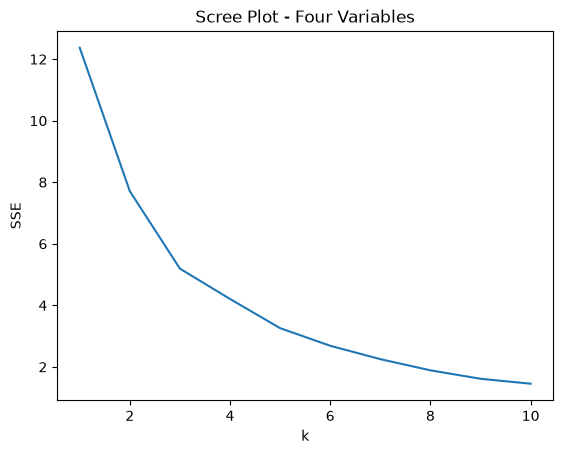

In [192]:
ks = np.arange(1, 11)
SSE3 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(all_X_scaled).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE3).set(
    title="Scree Plot - Four Variables",
    xlabel="k",
    ylabel="SSE"
)
plt.show()

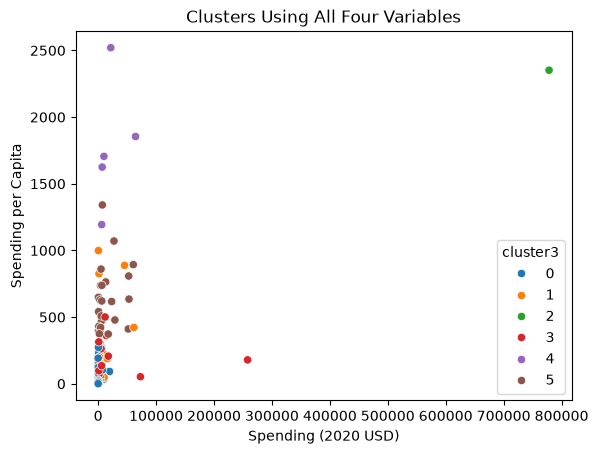

In [193]:
k3 = 6

km3 = KMeans(n_clusters=k3, max_iter=300, n_init=10, random_state=0)

df['cluster3'] = km3.fit_predict(all_X_scaled)

sns.scatterplot(
    data=df,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    hue='cluster3',
    palette='tab10'
)
plt.title('Clusters Using All Four Variables')
plt.show()

In [194]:
col3 = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
print(df.groupby('cluster3')[col3].describe())

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster3                                                                   
0                       65.0    1355.055919   3001.122751       8.622460   
1                       20.0    8627.700242  16201.555992     198.530037   
2                        1.0  778397.200000           NaN  778397.200000   
3                       33.0   12551.478136  45915.639096      23.306688   
4                        5.0   21878.058451  24674.937388    6095.708713   
5                       24.0   16005.656033  19478.059176     405.790494   

                                                                      \
                    25%            50%            75%            max   
cluster3                                                               
0             78.965006     239.887164    1074.134515   19591.209004   
1            623.936771    

In [195]:
print(df.loc[df['Country'].str.contains('United States of America')])

      index  Year                   Country  Spending (2020 USD)  \
5540   5540  2020  United States of America             778397.2   

      Percent of GDP  Percent of Government Spending  Spending per Capita  \
5540        0.037179                        0.081976          2351.631858   

      cluster1  cluster2  cluster3  
5540         3         1         2  


Since the content of AI’s output (mostly graphs and describe tables) matched what I got originally, all of my analysis for the questions still hold true.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements AI helped me with for this assignment was making my code more concise and efficient. AI did this by removing redundant lines of code for me and also by just coding solutions more efficiently (coded my graphs in less lines of code). In this assignment AI was also really helpful for helping me with data visualization as it outputted my scatterplots for question 1.2 all side by side, making it easier for me to compare them all. Additionally, AI also helped me plot my scree graphs for question 1.3 all on one graph, which made it easier for me to compare the scree plots. AI could do this well because AI is really good at coding and has access to more efficient coding methods that I myself do not know. AI limitations for this assignment would be the graph analyzation (deciding a k value from the scree graphs and reading the scatterplots for k Means). If I wanted AI to help me with those, I would either need to upload pictures of the graphs (which I couldn’t because of a usage limit) or try my best to describe the graphs accurately which is very prone to some human error and is also very tedious. However, since I had describe tables in my code output, I could feed those to AI instead which could help it analyze the scatterplots better. I verified the final solution by comparing AI’s output to my own code’s output to see if they matched and they basically did. I have no remaining concerns for this assignment.